# Figure 1A — CAID1 Disprot-PDB: MCC ranking

Disorder predictors from the first CAID round ranked by their per-residue Matthews correlation coefficient (MCC) on the Disprot-PDB reference set, with metapredict V1, V2 and V3 highlighted.

**How it is made.** CAID1 per-residue predictions are not distributed in a usable form, so the competing predictors' MCC values are the published CAID1 numbers (OpenEBench, column `dataset_default_thr_mcc`). metapredict V1–V3 are scored here from metapredict 3.1.0 predictions of the CAID1 Disprot-PDB targets (`data/metapredict_caid/` in the shared data directory), using 3.1.0's default binary calls (residues inside predicted IDRs are disordered).

**Output:** `figures/figure_1A.pdf`

In [1]:
import matplotlib.pyplot as plt

from caid_mcc import metapredict_mcc, plot_mcc_panel, read_caid_seq_disorder
from figtools import apply_style, require_metapredict_3_1, save_panel, shared_data_path

apply_style()
require_metapredict_3_1()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

caid1_dat = read_caid_seq_disorder(str(shared_data_path('caid_references', 'caid1_disorder_pdb.fasta')))

metapredict 3.1.0+6.ga1b28a7.dirty from /Users/alex/Dropbox/WASHU/Holehouse/tools/metapredict/metapredict/metapredict (git 7dcf52c)


In [2]:
# MCC at each method's default threshold, copied from CAID1:
# https://openebench.bsc.es/benchmarking/OEBC011/OEBX0110000002/participants
caid1_disprot_pdb_mcc = {'SPOT-Disorder2': 0.706, 'SPOT-Disorder1': 0.691, 'AUCpreD': 0.661, 'RawMSA': 0.624,
                         'SPOT-Disorder-Single': 0.614, 'DISOPRED-3-1': 0.609, 'AUCpreD-np': 0.597,
                         'IUPred-long': 0.587, 'IUPred2A-long': 0.583, 'IsUnstruct': 0.57, 'Predisorder': 0.568,
                         'IUPred2A-short': 0.559, 'IUPred-short': 0.555, 'MobiDB-lite': 0.551, 'ESpritz-X': 0.549,
                         'ESpritz-N': 0.536, 'VSL2B': 0.524, 'RONN': 0.518, 'DisoMine': 0.514, 'flDPlr': 0.512,
                         'PyHCA': 0.49, 'FoldUnfold': 0.462, 'flDPnn': 0.429, 'DisEMBL-465': 0.411,
                         'ESpritz-D': 0.407, 'GlobPlot': 0.326, 'S2D-2': 0.261, 'S2D-1': 0.26, 'DisEMBL-HL': 0.252,
                         'DisPredict-2': 0.232, 'DynaMine': 0.105, 'DFLpred': -0.029}

# metapredict V1-V3, scored from 3.1.0 predictions
caid1_disprot_pdb_mcc.update(metapredict_mcc('caid1', caid1_dat))
for name in ['metapredict V1', 'metapredict V2', 'metapredict V3']:
    print(f'{name}: MCC = {caid1_disprot_pdb_mcc[name]:.3f}')

metapredict V1: MCC = 0.623
metapredict V2: MCC = 0.715
metapredict V3: MCC = 0.714


Wrote figures/figure_1A.pdf


PosixPath('figures/figure_1A.pdf')

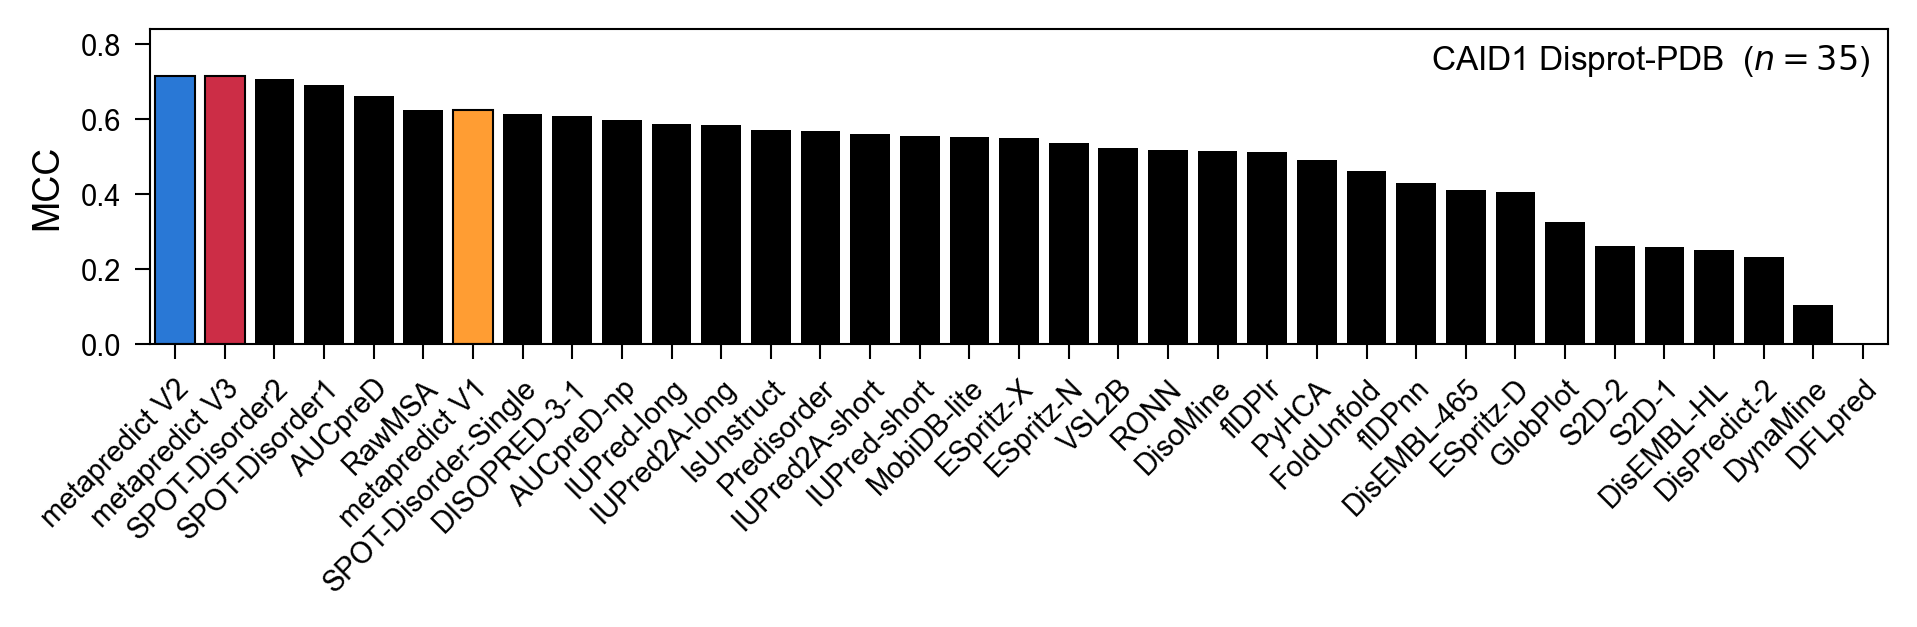

In [3]:
# Shared y-axis with 1B/1C. DFLpred (MCC = -0.029) sits just below zero and so has
# no visible bar, as in the published panel.
fig, ax = plt.subplots(figsize=(6.5, 2.2), dpi=150)
plot_mcc_panel(ax, caid1_disprot_pdb_mcc, 'CAID1 Disprot-PDB')
plt.tight_layout()
save_panel(fig, 'figure_1A')